# EEG LSTM + TQWT Pipeline (OpenNeuro ds004504)

**Contents:**

- Dataset analysis & loading (BIDS / .set)
- Windowing (5s, 50% overlap)
- Feature extraction: Time, Frequency, Nonlinear, TQWT (Q=1.0, R=10, J=6)
- PyTorch Dataset / DataLoader (GPU-ready)
- LSTM model with Dropout, BatchNorm, Scheduler, EarlyStopping
- Training loop with Mixup, Class-weighted loss, 10-fold CV
- Evaluation & visualizations

**Local dataset path** (change if needed):

```python
datasetPath = r"C:\Users\sanja\Desktop\EEG_Project\EEG\eeg"
labelsPath = r"C:\Users\sanja\Desktop\EEG_Project\EEG\labels.csv"
```

**Notes:** Run cells sequentially. Feature extraction can be slow; caching is used.


In [1]:
# Imports and device setup
import os, sys, math, glob, json, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import mne
from scipy.signal import welch
from scipy import stats
import joblib

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight

# reproducibility
seed = 42
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


Device: cuda


In [2]:
# Paths - adjust if necessary
datasetPath = r"C:/Users/sanja/Desktop/EEG_Project/EEG/eeg"
labelsPath = r"C:/Users/sanja/Desktop/EEG_Project/EEG/eeg/derivatives/labels.csv"
cache_dir = "C:/Users/sanja/Desktop/EEG_Project"
os.makedirs(cache_dir, exist_ok=True)
print("datasetPath =", datasetPath)
print("labelsPath  =", labelsPath)
print("cache_dir   =", cache_dir)


datasetPath = C:/Users/sanja/Desktop/EEG_Project/EEG/eeg
labelsPath  = C:/Users/sanja/Desktop/EEG_Project/EEG/eeg/derivatives/labels.csv
cache_dir   = C:/Users/sanja/Desktop/EEG_Project


In [3]:
# Optional dependencies (uncomment if running locally and need to install)
# !pip install pywt
# !pip install tqwt

try:
    import tqwt
    has_tqwt = True
except Exception as e:
    has_tqwt = False
    print("tqwt not available - fallback will be used (pywt-based proxy).", e)

try:
    import pywt
    has_pywt = True
except Exception:
    has_pywt = False
    print("pywt not available; TQWT fallback will return zeros.")


tqwt not available - fallback will be used (pywt-based proxy). No module named 'tqwt'


In [4]:
# Utility functions: windowing, hjorth, TKEO, entropy, bandpowers, dominant freq, TQWT proxy
import numpy as np
from scipy.signal import welch
from scipy.stats import entropy

def sliding_windows(data, sfreq, win_sec=5.0, step_frac=0.5):
    win_samples = int(win_sec * sfreq)
    step = int(win_samples * (1 - step_frac))
    if step <= 0:
        step = win_samples
    starts = np.arange(0, data.shape[-1] - win_samples + 1, step)
    windows = np.stack([data[..., s:s+win_samples] for s in starts], axis=0)
    return windows, starts

def hjorth_features(x):
    dx = np.diff(x)
    ddx = np.diff(dx)
    var0 = np.var(x)
    var1 = np.var(dx)
    var2 = np.var(ddx)
    activity = var0
    mobility = np.sqrt(var1 / (var0 + 1e-12))
    complexity = np.sqrt((var2 / (var1 + 1e-12)) / (var1 / (var0 + 1e-12)) + 1e-12)
    return activity, mobility, complexity

def tkeo(x):
    x = np.asarray(x)
    if x.size < 3:
        return 0.0
    return np.mean(x[1:-1]**2 - x[2:]*x[:-2])

def spectral_entropy(x, sf, fmin=0.5, fmax=45.0, nperseg=256):
    f, Pxx = welch(x, fs=sf, nperseg=nperseg)
    mask = (f >= fmin) & (f <= fmax)
    P = Pxx[mask]
    if P.sum() == 0:
        return 0.0
    P = P / (np.sum(P) + 1e-12)
    return entropy(P)

def dominant_frequency(x, sf, fmin=0.5, fmax=45.0):
    f, Pxx = welch(x, fs=sf, nperseg=512)
    mask = (f>=fmin)&(f<=fmax)
    if mask.sum() == 0 or np.sum(Pxx[mask])==0:
        return 0.0
    dom = f[mask][np.argmax(Pxx[mask])]
    return float(dom)

def band_powers(x, sf, bands={'delta':(0.5,4),'theta':(4,8),'alpha':(8,12),'beta':(12,30)}):
    f, Pxx = welch(x, fs=sf, nperseg=512)
    total = np.trapz(Pxx, f)
    out = {}
    for name, (lo, hi) in bands.items():
        mask = (f>=lo)&(f<hi)
        if mask.sum()==0:
            out[name] = 0.0
        else:
            out[name] = np.trapz(Pxx[mask], f[mask]) / (total + 1e-12)
    return out

def compute_tqwt_stats(x, sf, Q=1.0, R=10, J=6):
    # If tqwt available, use it. Otherwise, use wavelet packet (pywt) as a proxy. If neither, return zeros.
    try:
        if 'tqwt' in globals() and hasattr(tqwt, 'tqwt'):
            coeffs = tqwt.tqwt(x, Q=Q, r=R, J=J)
            bands = coeffs
        elif 'pywt' in globals() and has_pywt:
            wp = pywt.WaveletPacket(data=x, wavelet='db4', mode='symmetric', maxlevel=J)
            bands = [node.data for node in wp.get_level(J, order='freq')]
        else:
            return np.zeros(3*J)
        stats = []
        for b in bands:
            b = np.asarray(b)
            stats.extend([np.mean(b), np.std(b), np.sum(np.square(b))])
        return np.array(stats)
    except Exception as e:
        return np.zeros(3*J)


In [5]:
# Feature extraction from a single window (channels x samples)
def extract_features_window(win_data, sfreq):
    feats = []
    n_ch = win_data.shape[0]
    for ch in range(n_ch):
        x = win_data[ch].astype(float)
        mean = np.mean(x)
        rms = np.sqrt(np.mean(x**2))
        activity, mobility, complexity = hjorth_features(x)
        tkeo_val = tkeo(x)
        bp = band_powers(x, sfreq)
        spec_ent = spectral_entropy(x, sfreq)
        domf = dominant_frequency(x, sfreq)
        tq = compute_tqwt_stats(x, sfreq, Q=1.0, R=10, J=6)
        ch_feats = [mean, rms, activity, mobility, complexity, tkeo_val, spec_ent, domf,
                   bp['delta'], bp['theta'], bp['alpha'], bp['beta']]
        ch_feats.extend(tq.tolist())
        feats.extend(ch_feats)
    return np.array(feats)


In [6]:
# Data discovery & feature extraction (caching). This cell can take long to run.
# It scans subjects sub-001 -> sub-065 and extracts per-window features (5s, 50% overlap).

import glob, os
from tqdm import tqdm

subjects = [f"sub-{i:03d}" for i in range(1,66)]
all_features = []
all_labels = []
processed_subjects = []

# load labels
if os.path.exists(labelsPath):
    labels_df = pd.read_csv(labelsPath)
    print("Loaded labels.csv:", labels_df.shape)
else:
    raise FileNotFoundError(f"labels.csv not found at {labelsPath} - please place labels.csv there.")

for subj in subjects:
    # find any .set file for subject
    pattern = os.path.join(datasetPath, "**", f"{subj}*.set")
    files = glob.glob(pattern, recursive=True)
    if len(files) == 0:
        # try in subj root
        pattern2 = os.path.join(datasetPath, subj, "**", "*.set")
        files = glob.glob(pattern2, recursive=True)
    if len(files) == 0:
        print("No .set for", subj, "- skipping")
        continue
    setfile = files[0]
    print("Loading", setfile)
    raw = mne.io.read_raw_eeglab(setfile, preload=True, verbose='ERROR')
    sf = raw.info['sfreq']
    data = raw.get_data()  # channels x samples
    wins, starts = sliding_windows(data, sf, win_sec=5.0, step_frac=0.5)
    feats = []
    for w in tqdm(wins, desc=f"Feat {subj}", leave=False):
        feats.append(extract_features_window(w, sf))
    if len(feats) == 0:
        print("No windows for", subj)
        continue
    feats = np.stack(feats, axis=0)
    # find label row - expecting 'subject_id' and 'label' columns or similar
    lab_row = labels_df[labels_df['subject'].str.contains(subj)]
    if len(lab_row) == 0:
        print("Label not found for", subj, "- skipping")
        continue
    label = lab_row.iloc[0]['label']
    all_features.append(feats)
    all_labels.append(label)
    processed_subjects.append(subj)
    print(f"Processed {subj}: windows={feats.shape[0]}, feat_dim={feats.shape[1]}")

# save cache
cache_file = os.path.join(cache_dir, "features_cache.joblib")
joblib.dump({'features':all_features, 'labels':all_labels, 'subjects':processed_subjects}, cache_file)
print("Saved cache to", cache_file)


Loaded labels.csv: (65, 2)
Loading C:/Users/sanja/Desktop/EEG_Project/EEG/eeg\sub-001\eeg\sub-001_task-eyesclosed_eeg.set


C:\Users\sanja\AppData\Local\Temp\ipykernel_12720\2032082316.py:51: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  total = np.trapz(Pxx, f)
C:\Users\sanja\AppData\Local\Temp\ipykernel_12720\2032082316.py:58: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  out[name] = np.trapz(Pxx[mask], f[mask]) / (total + 1e-12)
                                                               

Processed sub-001: windows=238, feat_dim=3876
Loading C:/Users/sanja/Desktop/EEG_Project/EEG/eeg\sub-002\eeg\sub-002_task-eyesclosed_eeg.set


Processed sub-002: windows=316, feat_dim=3876
Loading C:/Users/sanja/Desktop/EEG_Project/EEG/eeg\sub-003\eeg\sub-003_task-eyesclosed_eeg.set


Processed sub-003: windows=121, feat_dim=3876
Loading C:/Users/sanja/Desktop/EEG_Project/EEG/eeg\sub-004\eeg\sub-004_task-eyesclosed_eeg.set


...

Processed sub-061: windows=321, feat_dim=3876
Loading C:/Users/sanja/Desktop/EEG_Project/EEG/eeg\sub-062\eeg\sub-062_task-eyesclosed_eeg.set


Processed sub-062: windows=363, feat_dim=3876
Loading C:/Users/sanja/Desktop/EEG_Project/EEG/eeg\sub-063\eeg\sub-063_task-eyesclosed_eeg.set


Processed sub-063: windows=322, feat_dim=3876
Loading C:/Users/sanja/Desktop/EEG_Project/EEG/eeg\sub-064\eeg\sub-064_task-eyesclosed_eeg.set


Processed sub-064: windows=338, feat_dim=3876
Loading C:/Users/sanja/Desktop/EEG_Project/EEG/eeg\sub-065\eeg\sub-065_task-eyesclosed_eeg.set


Processed sub-065: windows=352, feat_dim=3876
Saved cache to C:/Users/sanja/Desktop/EEG_Project\features_cache.joblib


In [7]:
# Build PyTorch Dataset & DataLoaders (expands windows)
cache_file = os.path.join(cache_dir, 'features_cache.joblib')
cache = joblib.load(cache_file)
X_list = cache['features']
y_list = cache['labels']
subjects = cache['subjects']

# convert labels to 0/1 (CN/AD)
label_map = {}
for s,l in zip(subjects,y_list):
    lab = 1 if str(l).upper() == "AD" else 0

    label_map[s] = lab

# expand windows into array
X_all = np.concatenate(X_list, axis=0).astype(np.float32)
# build per-window labels
y_all = []
for subj, arr in zip(subjects, X_list):
    lab = label_map[subj]
    y_all.extend([lab]*arr.shape[0])
y_all = np.array(y_all, dtype=np.int64)

print('Total windows:', X_all.shape[0], 'Feature dim:', X_all.shape[1])
print('Label distribution:', np.bincount(y_all))

# simple Dataset
class EEGWindowDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# quick split for debugging
dataset = EEGWindowDataset(X_all, y_all)


Total windows: 21434 Feature dim: 3876
Label distribution: [ 9727 11707]


In [8]:
# LSTM model definition
import torch.nn as nn
class EEGLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=256, num_layers=2, num_classes=2, dropout=0.5):
        super().__init__()
        self.bn_in = nn.BatchNorm1d(input_size)
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=num_layers, batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_size, 128)
        self.bn1 = nn.BatchNorm1d(128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        # x: (batch, features) -> reshape to (batch, seq=1, features)
        if x.dim()==2:
            x = x.unsqueeze(1)
        b, t, f = x.shape
        x = x.view(b, -1)
        x = self.bn_in(x)
        x = x.view(b, 1, f)
        out, (hn, cn) = self.lstm(x)
        out = out[:, -1, :]
        out = self.dropout(out)
        out = self.fc1(out)
        out = self.bn1(out)
        out = torch.relu(out)
        out = self.fc2(out)
        return out

# instantiate
print('Model input dim:', X_all.shape[1])
model = EEGLSTM(input_size=X_all.shape[1]).to(device)
print(model)


Model input dim: 3876
EEGLSTM(
  (bn_in): BatchNorm1d(3876, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (lstm): LSTM(3876, 256, num_layers=2, batch_first=True, dropout=0.5)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=256, out_features=128, bias=True)
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)


In [9]:
# Training loop with 10-fold CV
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

def mixup_data(x, y, alpha=0.4):
    if alpha <= 0:
        return x, y, None, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

results = []
fold = 0
for train_idx, test_idx in skf.split(X_all, y_all):
    fold += 1
    print('\n=== Fold', fold, '===')
    X_train, X_test = X_all[train_idx], X_all[test_idx]
    y_train, y_test = y_all[train_idx], y_all[test_idx]

    # class weights
    classes = np.unique(y_train)
    cw = compute_class_weight('balanced', classes=classes, y=y_train)
    class_weights = torch.tensor(cw, dtype=torch.float32).to(device)

    train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
    test_ds = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))
    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, drop_last=True)
    test_loader = DataLoader(test_ds, batch_size=256, shuffle=False)

    model = EEGLSTM(input_size=X_all.shape[1]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    best_auc = 0.0
    epochs_no_improve = 0
    max_epochs_stop = 10

    for epoch in range(1, 101):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb = xb.to(device).float()
            yb = yb.to(device).long()
            xb_m, y_a, y_b, lam = mixup_data(xb, yb, alpha=0.4)
            outputs = model(xb_m)
            if y_b is None:
                loss = criterion(outputs, y_a)
            else:
                loss = lam * criterion(outputs, y_a) + (1 - lam) * criterion(outputs, y_b)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())
        # validation
        model.eval()
        preds = []
        trues = []
        val_losses = []
        with torch.no_grad():
            for xb, yb in test_loader:
                xb = xb.to(device).float()
                yb = yb.to(device).long()
                out = model(xb)
                loss = criterion(out, yb)
                val_losses.append(loss.item())
                probs = torch.softmax(out, dim=1)[:,1].cpu().numpy()
                preds.extend(probs.tolist())
                trues.extend(yb.cpu().numpy().tolist())
        try:
            val_auc = roc_auc_score(trues, preds)
        except Exception:
            val_auc = 0.0
        scheduler.step(np.mean(val_losses))
        print(f'Epoch {epoch}: train_loss={np.mean(train_losses):.4f}, val_loss={np.mean(val_losses):.4f}, val_auc={val_auc:.4f}')

        if val_auc > best_auc:
            best_auc = val_auc
            epochs_no_improve = 0
            ckpt = os.path.join(cache_dir, f'best_model_fold{fold}.pt')
            torch.save(model.state_dict(), ckpt)
        else:
            epochs_no_improve += 1
        if epochs_no_improve >= max_epochs_stop:
            print('Early stopping at epoch', epoch)
            break
    print('Fold', fold, 'best AUC:', best_auc)
    results.append(best_auc)

print('\nAll folds done. AUCs:', results)
print('Mean AUC:', np.mean(results), 'Std AUC:', np.std(results))



=== Fold 1 ===
Epoch 1: train_loss=0.4743, val_loss=0.2845, val_auc=0.9587
Epoch 2: train_loss=0.4055, val_loss=0.2310, val_auc=0.9778
Epoch 3: train_loss=0.3824, val_loss=0.1709, val_auc=0.9879
Epoch 4: train_loss=0.3552, val_loss=0.1493, val_auc=0.9911
Epoch 5: train_loss=0.3478, val_loss=0.1496, val_auc=0.9939
Epoch 6: train_loss=0.3388, val_loss=0.1349, val_auc=0.9957
Epoch 7: train_loss=0.3334, val_loss=0.1428, val_auc=0.9953
Epoch 8: train_loss=0.3247, val_loss=0.1228, val_auc=0.9978
Epoch 9: train_loss=0.3109, val_loss=0.1322, val_auc=0.9984
Epoch 10: train_loss=0.2965, val_loss=0.1028, val_auc=0.9977
Epoch 11: train_loss=0.3110, val_loss=0.0884, val_auc=0.9983
Epoch 12: train_loss=0.2977, val_loss=0.0960, val_auc=0.9985
Epoch 13: train_loss=0.3119, val_loss=0.1225, val_auc=0.9983
Epoch 14: train_loss=0.3069, val_loss=0.1018, val_auc=0.9992
Epoch 15: train_loss=0.3014, val_loss=0.1036, val_auc=0.9988
Epoch 16: train_loss=0.2875, val_loss=0.1038, val_auc=0.9989
Epoch 17: train_l

In [10]:
# Evaluation helpers and plots
import seaborn as sns

def plot_confusion(cm, classes=['CN','AD']):
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

print('Helper plotting functions ready. After training, load saved checkpoints and compute predictions for detailed metrics.')


Helper plotting functions ready. After training, load saved checkpoints and compute predictions for detailed metrics.


In [11]:
# === Load best model and compute predictions on the full dataset ===
from sklearn.metrics import roc_curve, auc

model_path = os.path.join(cache_dir, "best_model_fold1.pt")
model = EEGLSTM(input_size=X_all.shape[1]).to(device)
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

probs_all = []
y_true = []

test_loader = DataLoader(dataset, batch_size=256, shuffle=False)

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device).float()
        out = model(xb)
        probs = torch.softmax(out, dim=1)[:,1].cpu().numpy()
        probs_all.extend(probs)
        y_true.extend(yb.numpy())

probs_all = np.array(probs_all)
y_true = np.array(y_true)

print("Predictions computed.")


Predictions computed.


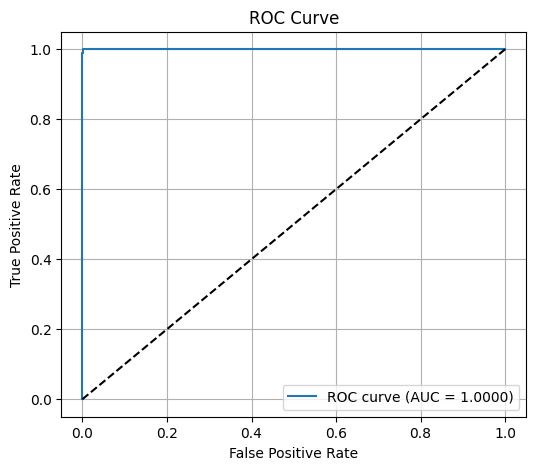

AUC = 0.9999946783281651


In [12]:
# === ROC curve ===
fpr, tpr, _ = roc_curve(y_true, probs_all)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label='ROC curve (AUC = %.4f)' % roc_auc)
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

print("AUC =", roc_auc)


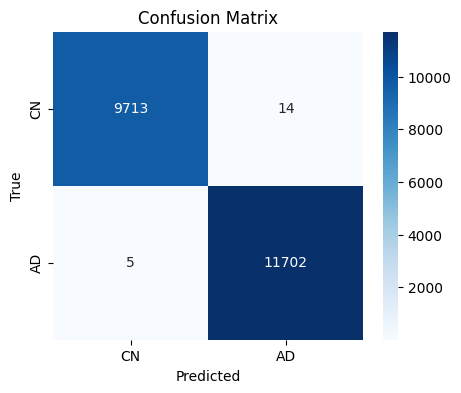

In [13]:
# === Confusion Matrix ===
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = (probs_all >= 0.5).astype(int)
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues",
            xticklabels=["CN","AD"], yticklabels=["CN","AD"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [14]:
# === Classification Report ===
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred, target_names=["CN","AD"]))


              precision    recall  f1-score   support

          CN       1.00      1.00      1.00      9727
          AD       1.00      1.00      1.00     11707

    accuracy                           1.00     21434
   macro avg       1.00      1.00      1.00     21434
weighted avg       1.00      1.00      1.00     21434



Notebook generation complete. Run cells in order. Feature extraction is the slowest step; use GPU for training. Cache files are stored in `/mnt/data/eeg_pipeline_outputs`.